# Desafio de Python: explorando dados de rastreamento  de formigas

## Desafio

Um programa de rastreamento (Ethoflow) registrou a posição de formigas ao longo de 30 minutos. Cada linha da planilha representa um registro de um indivíduo em um instante.
**Arquivo dos dados:** `Dados_deslocamento.csv`

As colunas principais são:

- `id`: identificação do indivíduo;
- `dir_x` e `dir_y`: coordenadas da posição no plano;
- `time`: tempo da observação, em segundos.

**Extra:** para usuários avançados, também podem explorar as colunas `distance` (distância registrada, em centímetros) e `stop` (indicador numérico de estado, 0 = parado ou 1 = movimento).

## Objetivos

1. Importar e ler os dados de um arquivo CSV.
2. Usar `print()`, `len()` e `set()` para resumir os registros e os indivíduos acompanhados.
- Contar o número de linhas (registros) da tabela; contar quantos indivíduos distintos existem; contar a quantidade de registros por indivíduo; mostrar os resultados na tela.
3. Fazer um gráfico: trajetória de um indivíduo ou das posições de todos os indivíduos em um instante.
4. Extra: Explorar as colunas `distance` e `stop`.

> **Antes de começar:** coloque `Dados_deslocamento.csv` na mesma pasta deste notebook. Os dados reais não foram incluídos neste notebook; o código será executado quando o arquivo estiver disponível no seu computador.


## Carregando as bibliotecas

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

## Carregando o arquivo .csv

In [3]:
df = pd.read_csv("/home/franciscoinacioo/Área de trabalho/Code_Club/Desafio_Jani/Dados_deslocamento.csv")        # se o separador for ";": sep=";"
print(df.head())                      # primeiras linhas
print(df.columns)                     # nomes das colunas

   Unnamed: 0  frame       pos_x       pos_y id     dir_x     dir_y  \
0          20     12  144.229885  158.063218  Z -0.971482 -0.237115   
1          21     12  273.647059  163.823529  D -0.663058 -0.748568   
2          22     12    6.529052  180.033639  X  0.174039 -0.984739   
3          23     12   49.260274   74.757991  N  0.611984 -0.790870   
4          24     12  139.238938   34.427729  Y -0.976307 -0.216391   

   distance_pixel  time  distance  ...  resting_time  number_mean_movement  \
0        0.212878   0.4  0.006495  ...    126.533333               12479.0   
1        0.621666   0.4  0.018966  ...    119.233333               12697.0   
2        2.581850   0.4  0.078768  ...    100.533333               13139.0   
3        1.514649   0.4  0.046210  ...    119.100000               12643.0   
4        2.206290   0.4  0.067311  ...    107.233333               13116.0   

   mean_movement_time  number_fast_movement  mean_fast_time  degree  \
0          415.966667            

## Análise dos Registros

In [4]:
# Número de linhas (registros)
n_registros = len(df)
print("Número de registros:", n_registros)

# Número de indivíduos distintos
individuos = set(df["id"])
print("Número de indivíduos:", len(individuos))

# Registros por indivíduo
contagem = df["id"].value_counts()
print("Registros por indivíduo:")
print(contagem)

Número de registros: 165168
Número de indivíduos: 10
Registros por indivíduo:
id
G    16656
Y    16648
Z    16646
N    16627
A    16596
D    16590
X    16572
H    16515
U    16457
S    15861
Name: count, dtype: int64


## Trajetória

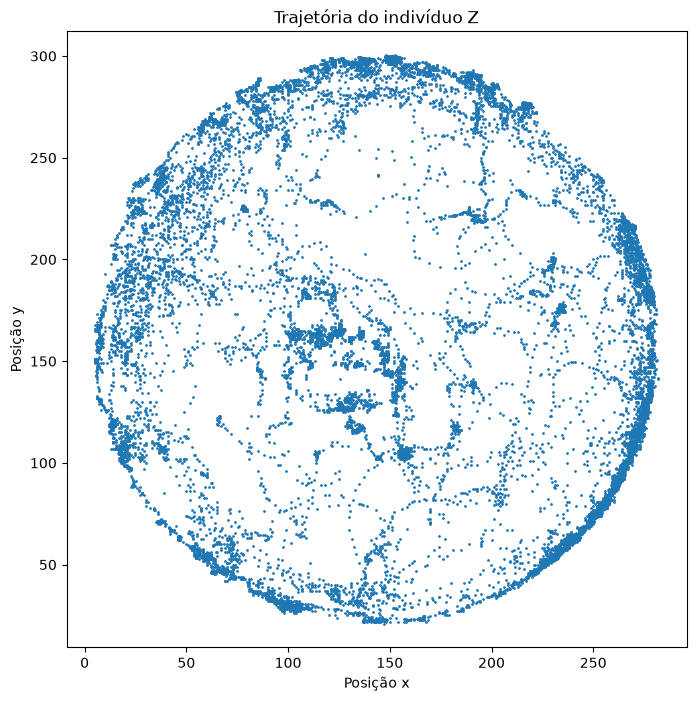

In [5]:
ind = "Z"              # escolhe o primeiro indivíduo (ou coloque o id desejado)
traj = df[df["id"] == ind]

plt.figure(figsize=(8, 8))
plt.plot(traj["pos_x"], traj["pos_y"], marker="o", markersize=1.0, linestyle="none")
plt.xlabel("Posição x")
plt.ylabel("Posição y")
plt.title(f"Trajetória do indivíduo {ind}")
plt.axis("equal")        # mantém a proporção, bom para placa de Petri
plt.show()

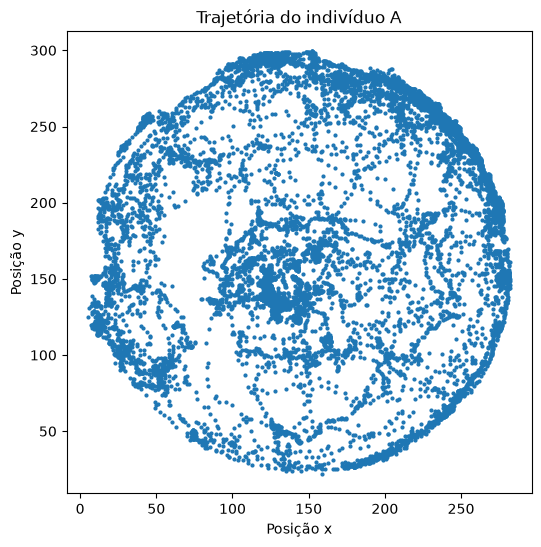

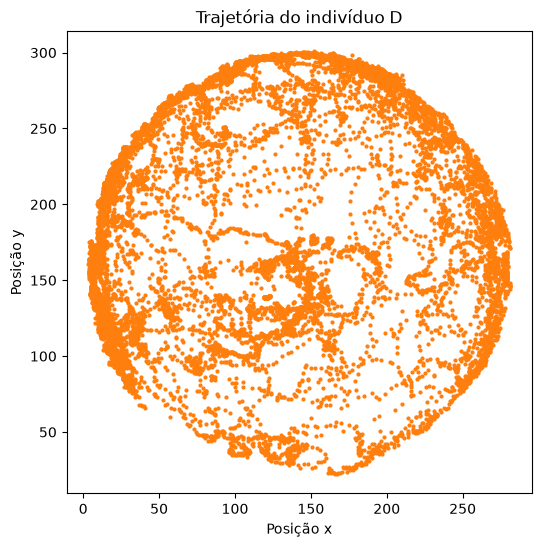

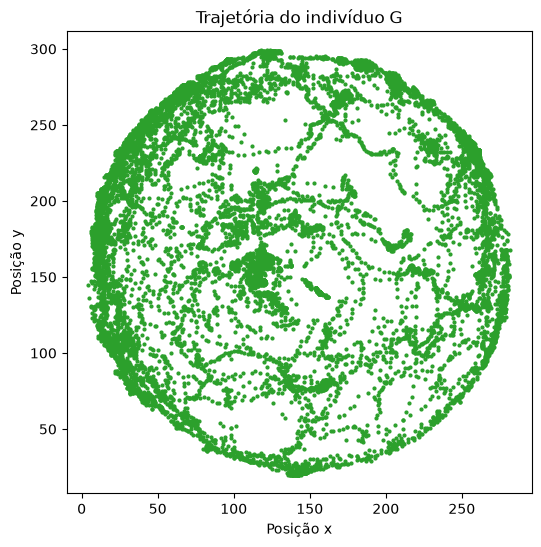

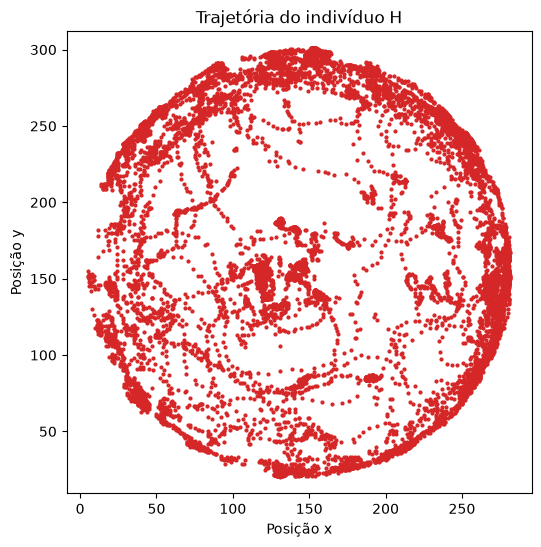

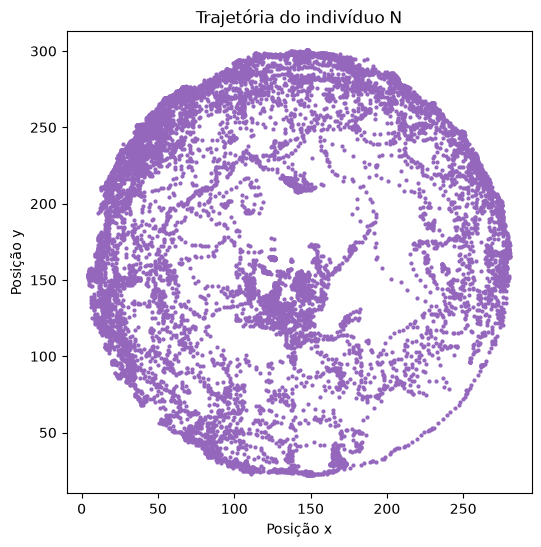

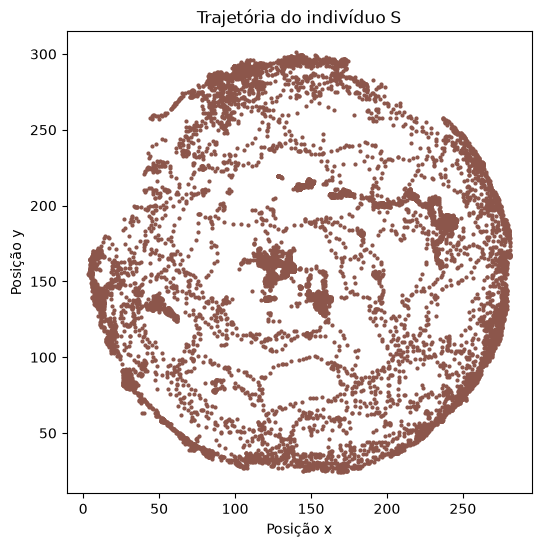

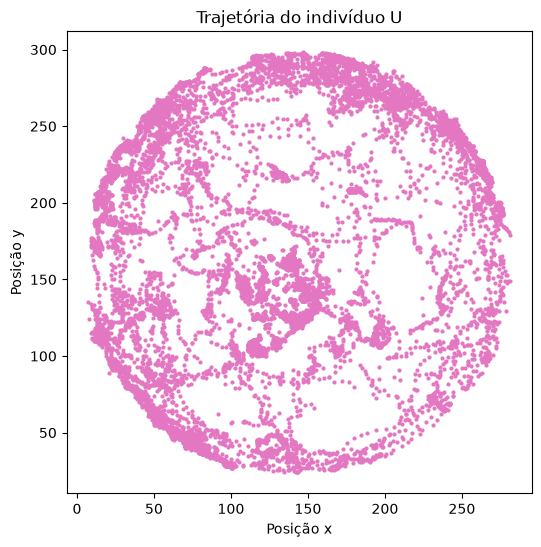

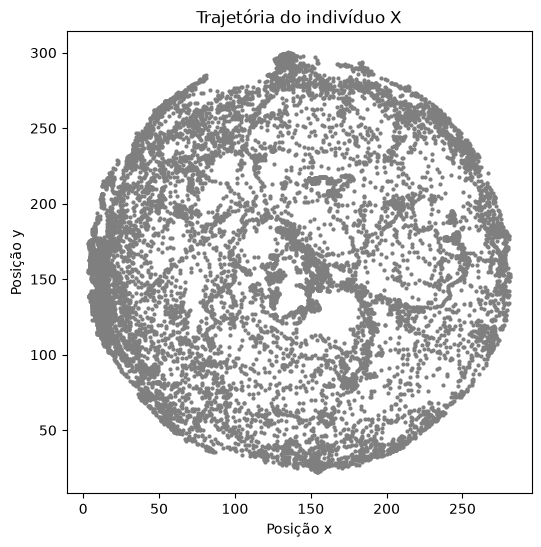

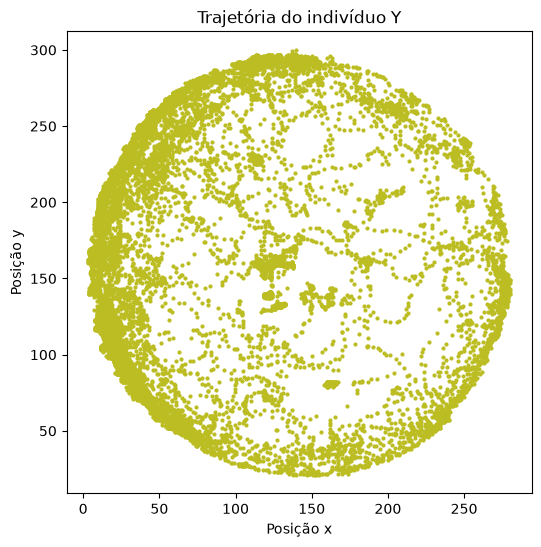

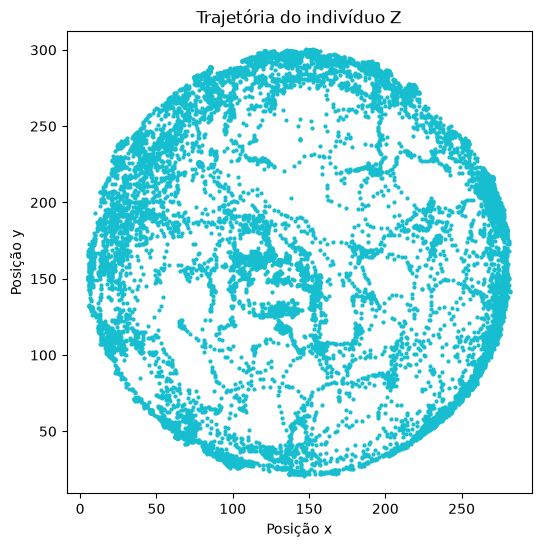

In [8]:
grupos = list(df.groupby("id"))
n = len(grupos)
cores = plt.cm.tab10.colors if n <= 10 else plt.cm.hsv(np.linspace(0, 1, n, endpoint=False))

for i, (ind, traj) in enumerate(grupos):
    plt.figure(figsize=(6, 6))
    plt.plot(traj["pos_x"], traj["pos_y"], marker="o", markersize=2,
             linestyle="none", color=cores[i % len(cores)])
    plt.xlabel("Posição x")
    plt.ylabel("Posição y")
    plt.title(f"Trajetória do indivíduo {ind}")
    plt.axis("equal")
    plt.show()

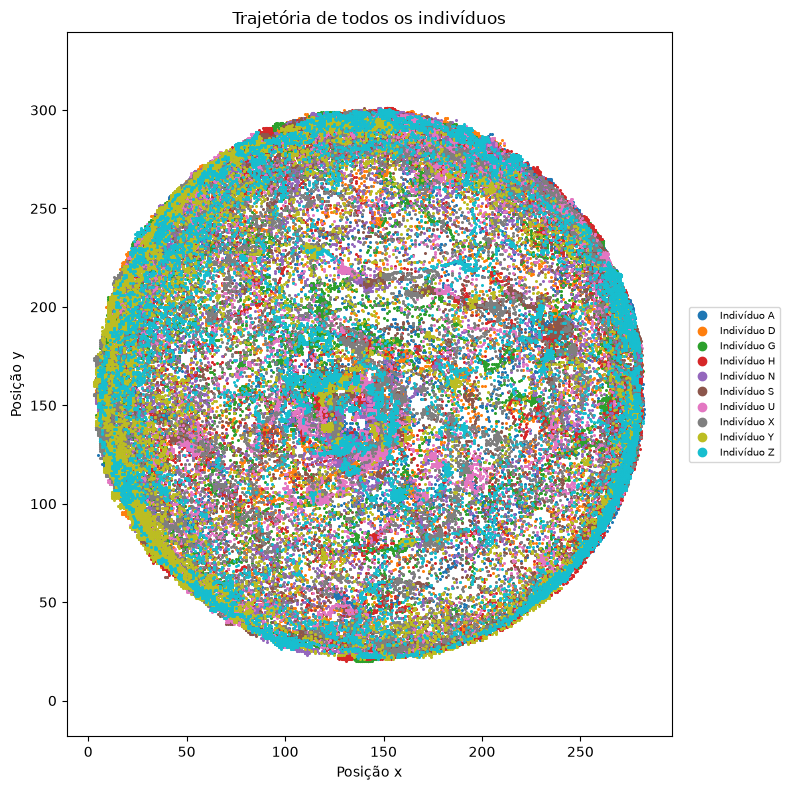

In [7]:
plt.figure(figsize=(8, 8))

for ind, traj in df.groupby("individuals"):
    plt.plot(traj["pos_x"], traj["pos_y"], marker="o", markersize=1.2,
             linestyle="none", label=f"Indivíduo {ind}")

plt.xlabel("Posição x")
plt.ylabel("Posição y")
plt.title("Trajetória de todos os indivíduos")
plt.axis("equal")        # mantém a proporção, bom para placa de Petri
plt.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5),
           markerscale=5)   # opcional; remova se tiver muitos indivíduos
plt.tight_layout()
plt.show()